# Task 3 - Frozen ImageNet backbone: Xception and ResNet-50

Protocol of the `transfer-learning` branch (`src/training/xception_aspect_frozen.py`, the run that introduced
this data pipeline), applied to both backbones. The ImageNet backbone is frozen and global-average pooled;
only a head is trained:

`features -> Dropout(0.45) -> Dense(512, ReLU) -> BatchNorm -> Dropout(0.2) -> Dense(4, softmax)`

AdamW (lr 5e-4, weight decay 1e-4), cross-entropy, batch 32, up to 30 epochs, ReduceLROnPlateau on val_loss
(x0.5, patience 2), early stopping after 6 epochs without a better val macro F1, best epoch by val macro F1.
Inputs are scaled the way each checkpoint was trained: [-1, 1] for Xception, caffe BGR mean subtraction for
ResNet-50.

Differences from the branch, which ran PyTorch: Xception is the Keras ImageNet checkpoint (the weights timm's
`legacy_xception` was converted from); ResNet-50 is the Keras ImageNet checkpoint (the original caffe weights,
about 75% top-1), not torchvision's `DEFAULT` weights (about 81%). The frozen backbone sees freshly augmented
images every epoch instead of one cached augmented view.

**Run.** This file is all it needs: it imports and reads no other file of the project.

1. Install: `pip install "tensorflow>=2.16" pandas pillow scikit-learn matplotlib jupyter` (Linux with an
   NVIDIA GPU: `"tensorflow[and-cuda]>=2.16"`). Tested with Python 3.11 and TensorFlow 2.21 / Keras 3.15 on an
   RTX 3050 6 GB, where it takes about 22 minutes; a CPU also works, much more slowly.
2. Run all cells. The data cell takes the Kaggle dataset `obulisainaren/forest-fire-c4` (version 2) from
   `DATASET_ROOT` (next cell) when it is set, else from a `data/` folder holding the dataset or its `.zip`,
   else downloads the `.zip` into `data/` (129 MB, public: no Kaggle account needed). It uses only images
   that are byte for byte the ones behind the reported results, and skips other copies (e.g. resized).
   Keras downloads the ImageNet weights the first time.
3. `data/`, `results/` and `models/` sit next to this notebook, or next to its folder when that folder is
   called `notebooks/`. Every run trained to the end leaves `models/<run>.weights.h5` (best epoch) and
   `models/<run>.fit.json` (its training record). With `USE_CHECKPOINTS = True` (next cell) a rerun reloads
   them instead of training again, so handing over those files as well skips the training.

## 0. Imports and settings

In [1]:
import hashlib
import json
import math
import os
import random
import re
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

# Folder holding train/, val/ and test/ of the Kaggle dataset "obulisainaren/forest-fire-c4" (version 2).
# None: $FOREST_FIRE_DATASET_ROOT when set, else the first folder holding exactly those images (checked byte for
# byte) in ROOT/data, ROOT/../dataset or /kaggle/input, else the .zip in ROOT/data, unpacked there and downloaded
# first when missing (public: no Kaggle account needed).
DATASET_ROOT = None
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # holds data/, results/ and models/
DATA_DIR, RESULTS_DIR, MODELS_DIR = ROOT / "data", ROOT / "results", ROOT / "models"
CLASS_NAMES = ["fire", "nofire", "smoke", "smokefire"]
IMAGE_SIZE, BATCH_SIZE, SEED = 224, 32, 42
MIXED_PRECISION = False
USE_CHECKPOINTS = True   # reload runs already trained to the end from models/ (see fit); False: always train

if int(keras.__version__.split(".")[0]) < 3:
    raise RuntimeError(f"Keras {keras.__version__} found; this notebook needs Keras 3 (pip install 'tensorflow>=2.16')")
# Checkpoints also hold the optimizer state, which reloading weights (to score, or to start stage 2) does not need.
warnings.filterwarnings("ignore", message="Skipping variable loading for optimizer")
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
keras.mixed_precision.set_global_policy("mixed_float16" if MIXED_PRECISION else "float32")
keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "none",
      "| precision:", keras.mixed_precision.global_policy().name)

I0000 00:00:1791650806.175334   86847 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791650806.574444   86847 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791650809.402423   86847 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | precision: float32


## 1. Data

The data pipeline is identical in all four notebooks:

1. **Split.** The Kaggle test split is kept untouched. The Kaggle train+val pool is re-split 800/200 per
   class, stratified by aspect group (width/height 0.9-1.1 `square`, 1.6-1.95 `wide`, else `other`), so
   validation also holds wide `smokefire` images. The split is rebuilt from the raw images on every run and
   checked against a fingerprint, so every notebook trains and scores on exactly the same images.
2. **Square crop from the raw image**, resized to 224x224 (bilinear, antialiased). Train takes a random
   crop (side 72-100% of the short side, random position), val/test the center crop. No stretching and no
   padding: in this dataset the image shape follows the class, so a stretched or padded image lets the model
   read the class from the shape.
3. **Train-only augmentation:** small affine (rotate +-5 deg, translate +-4%, scale 0.94-1.06, shear +-2 deg),
   horizontal flip, brightness and contrast x0.88-1.12.
4. **Aspect-balanced sampling:** every epoch draws 3,200 training images with replacement, with probability
   proportional to 1/sqrt(size of the image's (class, aspect group)).

Batches hold float32 pixels in [0, 255] and one-hot labels; the model rescales them in its first layers.

In [2]:
SPLITS = ["train", "val", "test"]
SPLIT_FINGERPRINT = "050511e885f8aa102b01112d79bcb5eb7146aada077af1f8912f8a5edab7f1ab"   # SHA-256 of the "filepath,split" lines
IMAGES_FINGERPRINT = "b3179773239fdb906ba89e795c687c7ad2a4d4699ac4125cae5f0b807da5e2ae"  # SHA-256 of the raw_sha256 lines
KAGGLE_URL = "https://www.kaggle.com/api/v1/datasets/download/obulisainaren/forest-fire-c4?datasetVersionNumber=2"


def datasets_in(folder):
    """Every folder, `folder` itself or up to three levels below it, that holds train/, val/ and test/."""
    for pattern in ("train", "*/train", "*/*/train", "*/*/*/train"):
        for train in sorted(Path(folder).glob(pattern)):
            if all((train.parent / name / "fire").is_dir() for name in SPLITS):
                yield train.parent


def unpack_kaggle_zip():
    """Unpack the .zip in DATA_DIR, downloading it from Kaggle first when there is none."""
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    archive = next(DATA_DIR.glob("*.zip"), None)
    if archive is None:
        archive, partial = DATA_DIR / "forest-fire-c4-v2.zip", DATA_DIR / "forest-fire-c4-v2.zip.part"
        print(f"Downloading the dataset (129 MB) from {KAGGLE_URL}")
        try:
            urllib.request.urlretrieve(KAGGLE_URL, partial)
        except OSError as error:
            raise RuntimeError(f'Download failed ({error}). By hand: curl -L -o "{archive}" "{KAGGLE_URL}"') from error
        partial.rename(archive)
    print("Unpacking", archive)
    with zipfile.ZipFile(archive) as zip_file:
        zip_file.extractall(DATA_DIR)
    return DATA_DIR


def aspect_group(width, height):
    ratio = width / height
    if 0.9 <= ratio <= 1.1:
        return "square"
    if 1.6 <= ratio <= 1.95:
        return "wide"
    return "other"


def scan_raw_images(root):
    """One row per raw image, in Kaggle split / class / file-name order."""
    pattern = re.compile(r"^(fire|nofire|smoke|smokefire)_(train|val|test)_\d+\.jpg$")
    rows = []
    for split in SPLITS:
        for label in CLASS_NAMES:
            for path in sorted((root / split / label).glob("*.jpg")):
                match = pattern.match(path.name)
                if not match or match.groups() != (label, split):
                    raise ValueError(f"Unexpected file name: {path}")
                with Image.open(path) as image:
                    width, height = image.size
                    image.verify()
                rows.append({"filepath": path.relative_to(root).as_posix(), "source_split": split, "label": label,
                              "class_index": CLASS_NAMES.index(label), "width": width, "height": height,
                              "aspect_group": aspect_group(width, height),
                              "raw_sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
    frame = pd.DataFrame(rows)
    if frame.raw_sha256.duplicated().any():
        raise ValueError("The raw dataset contains byte-identical duplicates")
    return frame


def validation_quotas(class_frame, fraction, min_wide):
    """Validation images per aspect group for one class."""
    groups = class_frame.aspect_group
    counts = {group: int((groups == group).sum()) for group in groups.unique()}
    target = round(len(class_frame) * fraction)
    exact = {group: count * fraction for group, count in counts.items()}
    quotas = {group: int(value) for group, value in exact.items()}
    order = sorted(counts, key=lambda g: (exact[g] - quotas[g], counts[g]), reverse=True)
    while sum(quotas.values()) < target:
        quotas[next(g for g in order if quotas[g] < counts[g])] += 1
    while sum(quotas.values()) > target:
        quotas[next(g for g in reversed(order) if quotas[g] > 0)] -= 1
    wanted = min(min_wide, counts.get("wide", 0))
    if quotas.get("wide", 0) < wanted:
        missing = wanted - quotas["wide"]
        quotas["wide"] = wanted
        for group in sorted((g for g in counts if g != "wide"), key=counts.get, reverse=True):
            take = min(missing, quotas[group])
            quotas[group] -= take
            missing -= take
    return quotas


def build_split(root, fraction=0.2, min_wide_smokefire_val=4, seed=SEED):
    """Kaggle test stays the test set; the Kaggle train+val pool is re-split per class and aspect group."""
    frame = scan_raw_images(root)
    pool = frame[frame.source_split != "test"]
    rng = random.Random(seed)
    val_index, group_number = [], 0
    for label in sorted(pool.label.unique()):
        class_frame = pool[pool.label == label]
        quotas = validation_quotas(class_frame, fraction, min_wide_smokefire_val if label == "smokefire" else 0)
        for group in sorted(quotas):
            index = class_frame.index[class_frame.aspect_group == group].tolist()
            rng.seed(seed + group_number)
            rng.shuffle(index)
            val_index += index[:quotas[group]]
            group_number += 1
    frame.insert(1, "split", np.where(frame.source_split == "test", "test", "train"))
    frame.loc[val_index, "split"] = "val"
    order = frame.split.map({split: i for i, split in enumerate(SPLITS)})
    return frame.iloc[np.argsort(order.to_numpy(), kind="stable")].reset_index(drop=True)


def verified_split(root):
    """The split of the images in `root`, or None unless they are byte for byte the images of the reported runs."""
    try:
        split = build_split(root)
    except (OSError, SyntaxError, ValueError):   # unreadable images or unexpected file names
        return None
    fingerprints = [hashlib.sha256("\n".join(lines).encode()).hexdigest()
                    for lines in (split.filepath + "," + split.split, split.raw_sha256)]
    return split if fingerprints == [SPLIT_FINGERPRINT, IMAGES_FINGERPRINT] else None


def load_dataset():
    """Raw images and split: the folder set by hand, else the first one found that holds exactly those images,
    else the Kaggle .zip unpacked into DATA_DIR. Copies with other bytes (resized, another version) are skipped."""
    by_hand = DATASET_ROOT or os.environ.get("FOREST_FIRE_DATASET_ROOT")
    for folder in [by_hand] if by_hand else [DATA_DIR, ROOT.parent / "dataset", Path("/kaggle/input"), None]:
        for root in datasets_in(folder or unpack_kaggle_zip()):   # None: unpack (and download) the .zip
            if (split := verified_split(root)) is not None:
                return root, split
            print("Skipped, not the raw images of Kaggle forest-fire-c4 version 2:", root)
    raise FileNotFoundError(f"No raw images of Kaggle forest-fire-c4 version 2 in {by_hand}" if by_hand else
                            f"The .zip unpacked into {DATA_DIR} is not Kaggle forest-fire-c4 version 2, or its unpack "
                            "was cut short: delete it and rerun")


dataset_root, split = load_dataset()
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
split.to_csv(RESULTS_DIR / "split_aspect.csv", index=False)
split["path"] = [str(dataset_root / p) for p in split.filepath]
frames = {name: split[split.split == name].reset_index(drop=True) for name in SPLITS}
print("dataset:", dataset_root)
pd.crosstab([split.split, split.label], split.aspect_group)

dataset: /home/minhquang/dataset/Forect Fire/Forest Fire_Dataset


aspect_group     other  square  wide
split label                         
test  fire           0     200     0
      nofire         0     200     0
      smoke         97       0   103
      smokefire    101       0    99
train fire           0     800     0
      nofire         9     781    10
      smoke        528      31   241
      smokefire     22     770     8
val   fire           0     200     0
      nofire         2     196     2
      smoke        132       8    60
      smokefire      6     190     4

In [3]:
def random_affine(image):
    uniform = lambda low, high: tf.random.uniform([], low, high)
    angle = uniform(-5.0, 5.0) * math.pi / 180
    shear_x, shear_y = uniform(-2.0, 2.0) * math.pi / 180, uniform(-2.0, 2.0) * math.pi / 180
    scale = uniform(0.94, 1.06)
    tx, ty = tf.round(IMAGE_SIZE * uniform(-0.04, 0.04)), tf.round(IMAGE_SIZE * uniform(-0.04, 0.04))
    rotation = tf.reshape(tf.stack([tf.cos(angle), -tf.sin(angle), tf.sin(angle), tf.cos(angle)]), [2, 2])
    shear = tf.reshape(tf.stack([1.0, tf.tan(shear_x), tf.tan(shear_y), 1.0]), [2, 2])
    inverse = tf.linalg.inv(scale * rotation @ shear)
    # ImageProjectiveTransform maps each output pixel back to its input pixel.
    center = (IMAGE_SIZE - 1) / 2
    shift = tf.stack([center, center]) - tf.linalg.matvec(inverse, tf.stack([center + tx, center + ty]))
    transform = tf.stack([inverse[0, 0], inverse[0, 1], shift[0], inverse[1, 0], inverse[1, 1], shift[1], 0.0, 0.0])
    return tf.raw_ops.ImageProjectiveTransformV3(
        images=image[None], transforms=transform[None], output_shape=[IMAGE_SIZE, IMAGE_SIZE],
        fill_value=0.0, interpolation="BILINEAR", fill_mode="CONSTANT")[0]


def augment(image):
    image = random_affine(image)
    image = tf.image.random_flip_left_right(image)
    image = tf.clip_by_value(image * tf.random.uniform([], 0.88, 1.12), 0.0, 255.0)
    mean = tf.reduce_mean(tf.image.rgb_to_grayscale(image))   # PIL-style contrast around the mean grey
    return tf.clip_by_value(mean + tf.random.uniform([], 0.88, 1.12) * (image - mean), 0.0, 255.0)


def load(path, height, width, label, training):
    if training:
        short = tf.cast(tf.minimum(height, width), tf.float32)
        side = tf.maximum(1, tf.cast(tf.round(short * tf.random.uniform([], 0.72, 1.0)), tf.int32))
        top = tf.random.uniform([], 0, height - side + 1, dtype=tf.int32)
        left = tf.random.uniform([], 0, width - side + 1, dtype=tf.int32)
    else:
        side = tf.minimum(height, width)
        top, left = (height - side) // 2, (width - side) // 2
    image = tf.io.decode_and_crop_jpeg(tf.io.read_file(path), tf.stack([top, left, side, side]), channels=3)
    image = tf.image.resize(image, [IMAGE_SIZE, IMAGE_SIZE], antialias=True)
    if training:
        image = augment(image)
    return image, tf.one_hot(label, len(CLASS_NAMES))


def make_dataset(frame, training=False, seed=SEED):
    """Batched dataset; val/test keep the split order so predictions line up with `frame`."""
    columns = (frame.path.to_numpy(), frame.height.to_numpy("int32"),
               frame.width.to_numpy("int32"), frame.class_index.to_numpy("int32"))
    if training:
        counts = frame.groupby(["label", "aspect_group"]).label.transform("size").to_numpy()
        probabilities = (1 / np.sqrt(counts)) / (1 / np.sqrt(counts)).sum()
        rng = np.random.default_rng(seed)
        tensors = [tf.constant(column) for column in columns]
        draws = tf.data.Dataset.from_generator(lambda: rng.choice(len(frame), size=len(frame), p=probabilities),
                                               output_signature=tf.TensorSpec([], tf.int64))
        draws = draws.apply(tf.data.experimental.assert_cardinality(len(frame)))   # lets Keras count the steps
        dataset = draws.map(lambda i: tuple(tf.gather(t, i) for t in tensors))
    else:
        dataset = tf.data.Dataset.from_tensor_slices(columns)
    dataset = dataset.map(lambda *row: load(*row, training=training), num_parallel_calls=tf.data.AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


datasets = {name: make_dataset(frames[name], training=(name == "train")) for name in SPLITS}
{name: len(frame) for name, frame in frames.items()}

I0000 00:00:1791650813.390719   86847 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3618 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


{'train': 3200, 'val': 800, 'test': 800}

## 2. Training and evaluation helpers

Every run keeps its best epoch on validation and reloads it; test is predicted once, after training. Each
run writes `results/<run>/` (`metrics.json`, `history.csv`, val/test predictions, `summary.png`) and one
row of `results/leaderboard.csv`.

In [4]:
def compile_model(model, optimizer, loss="categorical_crossentropy"):
    # No XLA: it asks for one 3.9 GB buffer when the whole Xception is unfrozen on a 6 GB GPU.
    model.compile(optimizer=optimizer, loss=loss, jit_compile=False,
                  metrics=["accuracy", keras.metrics.F1Score(average="macro", name="f1")])


def count_params(model):
    return model.count_params(), int(sum(np.prod(w.shape) for w in model.trainable_weights))


def fit(model, run, epochs, monitor="val_loss", early_stopping=None, reduce_lr=None):
    """Train, keep the best epoch by `monitor` and reload it.

    early_stopping: patience on `monitor`, or None. reduce_lr: ReduceLROnPlateau(val_loss) arguments, or None.
    A run trained to the end leaves models/<run>.weights.h5 (best epoch) and models/<run>.fit.json (its history
    and these arguments). With USE_CHECKPOINTS, a run that has both, for the same arguments, is reloaded instead.
    """
    mode = "max" if monitor == "val_f1" else "min"
    run_dir = RESULTS_DIR / run
    run_dir.mkdir(parents=True, exist_ok=True)
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    checkpoint, record = MODELS_DIR / f"{run}.weights.h5", MODELS_DIR / f"{run}.fit.json"
    arguments = {"epochs": epochs, "monitor": monitor, "early_stopping": early_stopping, "reduce_lr": reduce_lr}
    if USE_CHECKPOINTS and checkpoint.exists() and record.exists():
        saved = json.loads(record.read_text(encoding="utf-8"))
        if saved.pop("arguments") == arguments:
            model.load_weights(checkpoint)
            history = pd.DataFrame(saved.pop("history"),
                                   index=pd.RangeIndex(1, saved["epochs_run"] + 1, name="epoch"))
            print(f"{run}: reloaded {checkpoint.name} instead of training (USE_CHECKPOINTS = False retrains). "
                  f"Log of that training ({saved['train_minutes']} min):")
            for epoch, row in history.iterrows():   # Keras' format, without the timings
                best = f" - best {monitor}: the reloaded weights" if epoch == saved["best_epoch"] else ""
                print(f"Epoch {epoch}/{epochs}{best}\n"
                      + " - ".join(f"{k}: {v:.4f}" if v > 1e-3 else f"{k}: {v:.4e}" for k, v in row.items()))
            return {"history": history, **saved}
        print(f"{run}: the fit arguments differ from those in {record.name}, so it is retrained")
    record.unlink(missing_ok=True)   # the checkpoint is overwritten from the first epoch on
    callbacks = [keras.callbacks.ModelCheckpoint(checkpoint, monitor=monitor, mode=mode,
                                                 save_best_only=True, save_weights_only=True),
                 keras.callbacks.CSVLogger(run_dir / "history.csv")]
    if early_stopping:
        callbacks.append(keras.callbacks.EarlyStopping(monitor=monitor, mode=mode, patience=early_stopping))
    if reduce_lr:
        callbacks.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", **reduce_lr))
    started = time.time()
    history = model.fit(datasets["train"], validation_data=datasets["val"], epochs=epochs,
                        callbacks=callbacks, shuffle=False, verbose=2)   # the train dataset samples itself
    minutes = (time.time() - started) / 60
    model.load_weights(checkpoint)
    history = pd.DataFrame(history.history, index=pd.RangeIndex(1, len(history.history["loss"]) + 1, name="epoch"))
    best = history[monitor].idxmax() if mode == "max" else history[monitor].idxmin()
    fit_info = {"monitor": monitor, "best_epoch": int(best), "epochs_run": len(history),
                "train_minutes": round(minutes, 1)}
    saved = {**fit_info, "arguments": arguments, "history": history.astype(float).to_dict("list")}
    record.write_text(json.dumps(saved) + "\n", encoding="utf-8")
    return {"history": history, **fit_info}


def score_split(model, name):
    frame = frames[name]
    probabilities = model.predict(datasets[name], verbose=0)
    truth, predicted = frame.class_index.to_numpy(), probabilities.argmax(1)
    report = classification_report(truth, predicted, labels=range(len(CLASS_NAMES)), target_names=CLASS_NAMES,
                                   output_dict=True, zero_division=0)
    matrix = confusion_matrix(truth, predicted, labels=range(len(CLASS_NAMES)))
    predictions = frame[["filepath", "label", "aspect_group"]].assign(
        predicted=[CLASS_NAMES[i] for i in predicted], confidence=probabilities.max(1).round(4))
    by_aspect = (predictions.assign(correct=predictions.label == predictions.predicted)
                 .groupby(["label", "aspect_group"]).correct.agg(["mean", "size"]))
    metrics = {"accuracy": report["accuracy"], "macro_f1": report["macro avg"]["f1-score"],
               "per_class": {c: {k: report[c][k] for k in ("precision", "recall", "f1-score")} for c in CLASS_NAMES},
               "confusion_matrix": matrix.tolist(),
               "recall_by_label_and_aspect": {f"{label}/{group}": {"recall": round(row["mean"], 4), "n": int(row["size"])}
                                              for (label, group), row in by_aspect.iterrows()}}
    return metrics, predictions, matrix


def plot_run(run, fit_info, matrices, path):
    history = fit_info["history"]
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
    for ax, metric in zip(axes[:2], ("loss", "f1")):
        ax.plot(history.index, history[metric], marker=".", label="train")
        ax.plot(history.index, history[f"val_{metric}"], marker=".", label="val")
        ax.axvline(fit_info["best_epoch"], color="grey", linestyle=":", label="best epoch")
        ax.set(title=metric if metric == "loss" else "macro F1", xlabel="epoch")
        ax.legend()
    for ax, name in zip(axes[2:], ("val", "test")):
        matrix = matrices[name]
        ax.imshow(matrix, cmap="Blues")
        for i, j in np.ndindex(matrix.shape):
            ax.text(j, i, matrix[i, j], ha="center", va="center",
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black")
        ax.set(xticks=range(len(CLASS_NAMES)), yticks=range(len(CLASS_NAMES)), xticklabels=CLASS_NAMES,
               yticklabels=CLASS_NAMES, xlabel="predicted", ylabel="true", title=f"{name} confusion")
    fig.suptitle(run)
    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.show()


def evaluate(model, run, task, fit_info, settings):
    """Score val and test, write results/<run>/ and update results/leaderboard.csv."""
    run_dir = RESULTS_DIR / run
    total, trainable = count_params(model)
    report = {"task": task, "run": run, "settings": settings, "total_params": total, "trainable_params": trainable,
              **{k: v for k, v in fit_info.items() if k != "history"}}
    matrices = {}
    for name in ("val", "test"):
        report[name], predictions, matrices[name] = score_split(model, name)
        predictions.to_csv(run_dir / f"{name}_predictions.csv", index=False)
    (run_dir / "metrics.json").write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    plot_run(run, fit_info, matrices, run_dir / "summary.png")
    test, cm, i = report["test"], matrices["test"], CLASS_NAMES.index
    row = {"task": task, "run": run, "trainable_params": trainable, "total_params": total,
           "best_epoch": report["best_epoch"], "epochs_run": report["epochs_run"],
           "train_minutes": report["train_minutes"], "val_acc": report["val"]["accuracy"],
           "val_f1": report["val"]["macro_f1"], "test_acc": test["accuracy"], "test_f1": test["macro_f1"],
           **{f"test_f1_{c}": test["per_class"][c]["f1-score"] for c in CLASS_NAMES},
           "test_smokefire_as_smoke": int(cm[i("smokefire"), i("smoke")]),
           "test_fire_as_smokefire": int(cm[i("fire"), i("smokefire")]),
           "test_fire_or_smokefire_as_nofire": int(cm[i("fire"), i("nofire")] + cm[i("smokefire"), i("nofire")])}
    path = RESULTS_DIR / "leaderboard.csv"
    board = pd.read_csv(path) if path.exists() else pd.DataFrame()
    board = board[board.run != run] if not board.empty else board
    pd.concat([board, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False, float_format="%.4f")
    return pd.Series(row)

ImageNet backbones from `keras.applications`, global-average pooled:

In [5]:
# name: (Keras constructor, input scaling its ImageNet weights expect, first layer of the last stage)
BACKBONES = {
    "xception": (keras.applications.Xception,
                 lambda: layers.Rescaling(1 / 127.5, offset=-1, name="to_minus1_1"), "block13"),
    "resnet50": (keras.applications.ResNet50,
                 lambda: layers.Lambda(keras.applications.resnet50.preprocess_input, name="caffe_bgr"), "conv5_"),
}


def backbone(name):
    """Frozen ImageNet backbone with global average pooling, and its input-scaling layer."""
    constructor, preprocess, _ = BACKBONES[name]
    base = constructor(include_top=False, weights="imagenet", input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), pooling="avg")
    base.trainable = False
    return base, preprocess()

## 3. Model

In [6]:
def build_frozen(name):
    base, preprocess = backbone(name)
    inputs = keras.Input((IMAGE_SIZE, IMAGE_SIZE, 3))
    x = base(preprocess(inputs), training=False)
    x = layers.Dropout(0.45)(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.BatchNormalization(momentum=0.9, epsilon=1e-5)(x)   # PyTorch BatchNorm1d defaults
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(len(CLASS_NAMES), activation="softmax")(x)
    return keras.Model(inputs, outputs, name=f"frozen_{name}")


settings = {"source": "transfer-learning branch, xception_aspect_frozen.py protocol",
            "head": "Dropout 0.45 - Dense 512 ReLU - BatchNorm - Dropout 0.2 - Dense 4",
            "optimizer": "AdamW 5e-4, weight decay 1e-4", "loss": "categorical cross-entropy", "epochs": 30,
            "early_stopping": "val macro F1, patience 6", "reduce_lr": "val_loss x0.5, patience 2",
            "selection": "val macro F1"}

## 4. Train and evaluate both backbones

=== frozen_xception: 1,052,164 trainable parameters
Epoch 1/30


I0000 00:00:1791650817.751009   86847 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


I0000 00:00:1791650821.427670   86999 cuda_dnn.cc:461] Loaded cuDNN version 92000


100/100 - 37s - 371ms/step - accuracy: 0.6984 - f1: 0.6905 - loss: 0.8387 - val_accuracy: 0.7875 - val_f1: 0.7841 - val_loss: 0.6082 - learning_rate: 5.0000e-04


Epoch 2/30


...

100/100 - 28s - 276ms/step - accuracy: 0.8628 - f1: 0.8558 - loss: 0.3455 - val_accuracy: 0.9013 - val_f1: 0.9013 - val_loss: 0.2549 - learning_rate: 3.1250e-05


Epoch 27/30


100/100 - 26s - 264ms/step - accuracy: 0.8781 - f1: 0.8755 - loss: 0.3224 - val_accuracy: 0.8950 - val_f1: 0.8952 - val_loss: 0.2592 - learning_rate: 3.1250e-05


Epoch 28/30


100/100 - 25s - 248ms/step - accuracy: 0.8709 - f1: 0.8673 - loss: 0.3344 - val_accuracy: 0.9038 - val_f1: 0.9039 - val_loss: 0.2502 - learning_rate: 1.5625e-05


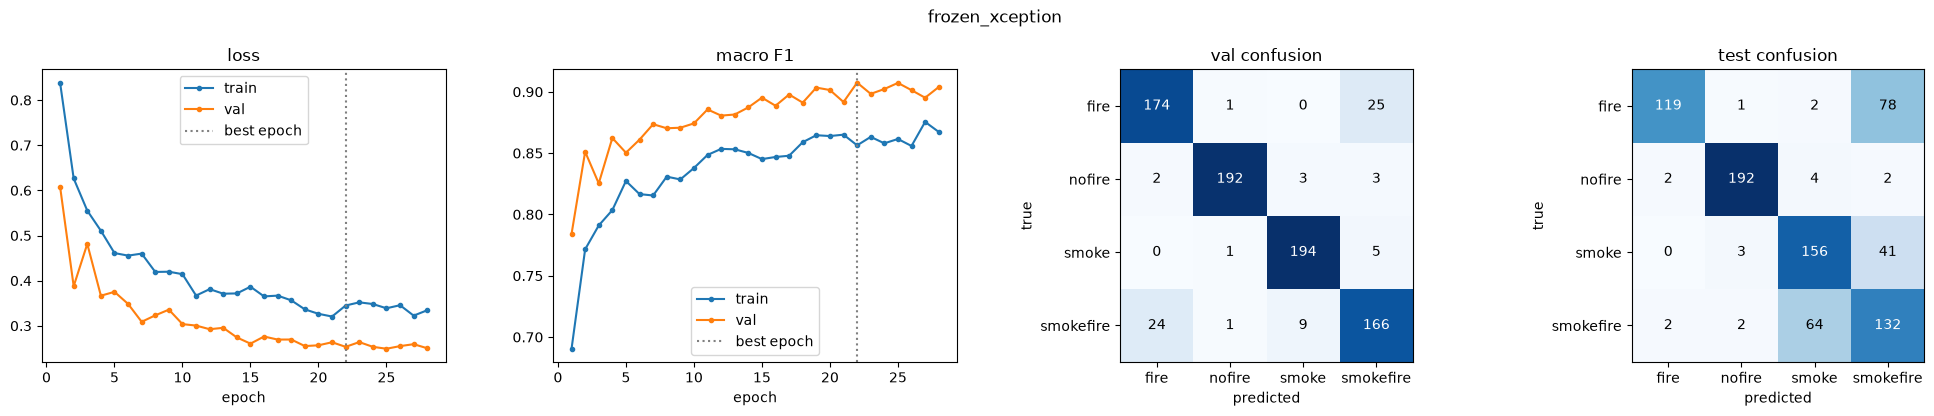

=== frozen_resnet50: 1,052,164 trainable parameters
Epoch 1/30


100/100 - 29s - 288ms/step - accuracy: 0.7647 - f1: 0.7582 - loss: 0.6373 - val_accuracy: 0.9013 - val_f1: 0.9016 - val_loss: 0.2944 - learning_rate: 5.0000e-04


Epoch 2/30


100/100 - 25s - 251ms/step - accuracy: 0.8359 - f1: 0.8301 - loss: 0.4603 - val_accuracy: 0.9000 - val_f1: 0.8999 - val_loss: 0.2873 - learning_rate: 5.0000e-04


Epoch 3/30


...

100/100 - 27s - 271ms/step - accuracy: 0.9141 - f1: 0.9094 - loss: 0.2192 - val_accuracy: 0.9388 - val_f1: 0.9390 - val_loss: 0.1664 - learning_rate: 1.2500e-04


Epoch 15/30


100/100 - 43s - 434ms/step - accuracy: 0.9078 - f1: 0.9020 - loss: 0.2378 - val_accuracy: 0.9413 - val_f1: 0.9413 - val_loss: 0.1478 - learning_rate: 1.2500e-04


Epoch 16/30


100/100 - 27s - 273ms/step - accuracy: 0.9125 - f1: 0.9098 - loss: 0.2097 - val_accuracy: 0.9413 - val_f1: 0.9413 - val_loss: 0.1540 - learning_rate: 1.2500e-04


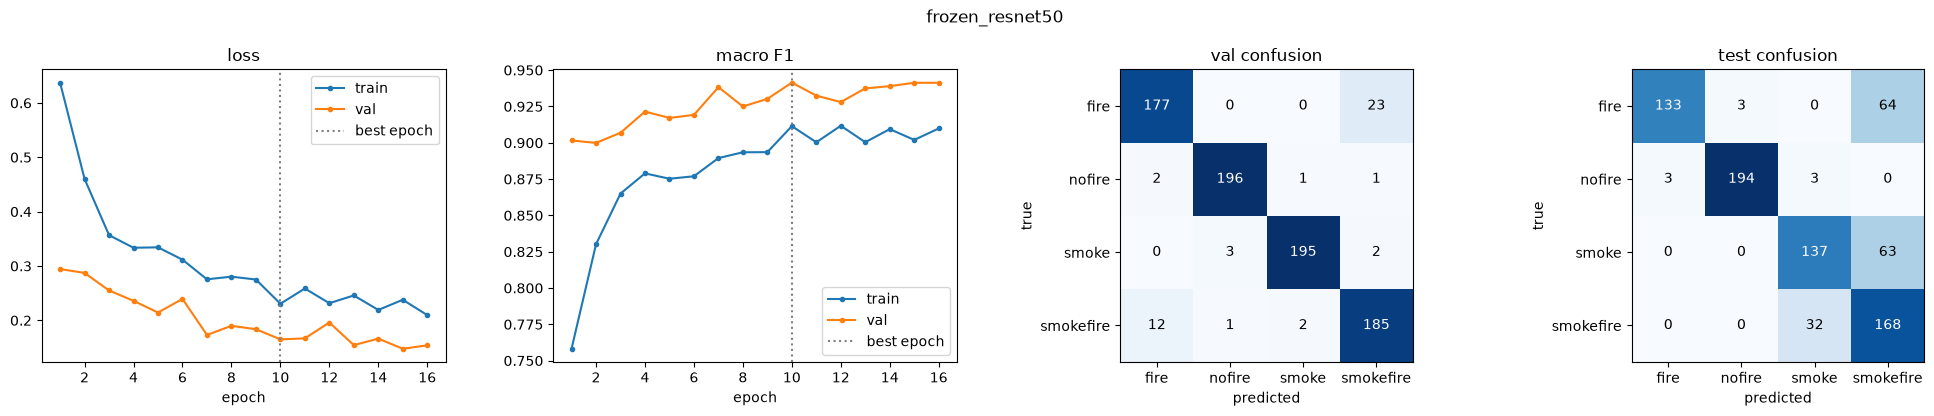

,task,run,trainable_params,total_params,best_epoch,epochs_run,train_minutes,val_acc,val_f1,test_acc,test_f1,test_f1_fire,test_f1_nofire,test_f1_smoke,test_f1_smokefire,test_smokefire_as_smoke,test_fire_as_smokefire,test_fire_or_smokefire_as_nofire
0,3 frozen backbone,frozen_xception,1052164,21914668,22,28,13.3,0.90750,0.907474,0.74875,0.754211,0.736842,0.964824,0.732394,0.582781,64,78,3
1,3 frozen backbone,frozen_resnet50,1052164,24640900,10,16,7.5,0.94125,0.941378,0.79000,0.796086,0.791667,0.977330,0.736559,0.678788,32,64,3


In [7]:
rows = []
for name in BACKBONES:
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model = build_frozen(name)
    compile_model(model, keras.optimizers.AdamW(5e-4, weight_decay=1e-4))
    run = f"frozen_{name}"
    print(f"=== {run}: {count_params(model)[1]:,} trainable parameters")
    fit_info = fit(model, run, epochs=30, monitor="val_f1", early_stopping=6, reduce_lr=dict(factor=0.5, patience=2))
    rows.append(evaluate(model, run, "3 frozen backbone", fit_info, {**settings, "backbone": name}))
pd.DataFrame(rows)

## All runs in `results/leaderboard.csv`

In [8]:
board = pd.read_csv(RESULTS_DIR / "leaderboard.csv")
board[["task", "run", "trainable_params", "best_epoch", "val_acc", "val_f1", "test_acc", "test_f1",
       "test_f1_smokefire", "test_smokefire_as_smoke", "test_fire_as_smokefire"]].round(4)

,task,run,trainable_params,best_epoch,val_acc,val_f1,test_acc,test_f1,test_f1_smokefire,test_smokefire_as_smoke,test_fire_as_smokefire
0,1 basic NN,basic_nn,3179652,11,0.6875,0.6806,0.6225,0.6245,0.4859,94,40
1,2 custom CNN,custom_cnn,2740408,47,0.9337,0.9339,0.7725,0.7748,0.6800,30,67
2,3 frozen backbone,frozen_xception,1052164,22,0.9075,0.9075,0.7488,0.7542,0.5828,64,78
3,3 frozen backbone,frozen_resnet50,1052164,10,0.9413,0.9414,0.7900,0.7961,0.6788,32,64
